# Axion Challenge, wykład $3$ (QML): głębokość ansatzu $L$ a accuracy

Implementacja sekcji „Plan eksperymentu” z [README.md](README.md): $2$-kubitowy variational classifier na `make_moons`, $L \in \{1, \ldots, 8\}$, $5$ seedów, trening Adam + parameter-shift na `StatevectorEstimator`.

### Doprecyzowania i odstępstwa od planu
Planu nie zmieniałem. Poniżej miejsca, w których plan czegoś nie określa i trzeba było wybrać:
- **Skalowanie:** `MinMaxScaler` do $[0, \pi]$ jest dopasowany tylko na train, więc punkty testowe mogą lekko wyjść poza $[0, \pi]$ (zakresy wypisane w sekcji $2$). Nie przycinam ich.
- **Numeracja epok w historii:** epoka $0$ to parametry startowe, epoka $e$ to parametry po $e$ krokach Adama. Run ma $100$ kroków, więc w `history.csv` są epoki $0$–$100$, a wynik końcowy (`final.csv`) to epoka $100$. Train loss/acc w epoce $e$ pochodzą z tego samego wywołania `est.run`, które liczy gradient do kroku $e+1$, więc nie kosztują dodatkowych obwodów.
- **Jedno `est.run` na epokę** z $2$ PUB-ami: train ($f(\theta)$ i wszystkie przesunięcia $\pm\pi/2$, każde $\times\, 200$ punktów) oraz test ($f(\theta)$ $\times\, 200$ punktów).
- **Równoległość:** $40$ runów ($L \times$ seed) jest od siebie niezależnych, więc w sekcji $6$ liczę je równolegle w osobnych procesach (`joblib`). Każdy run jest deterministyczny (statevector, inicjalizacja z seeda), więc wyniki są identyczne jak przy liczeniu po kolei.
- **Std:** odchylenie standardowe po $5$ seedach, $\mathrm{ddof} = 1$ (domyślne w pandas).
- **Dodatkowy pakiet:** `pylatexenc`, bo wymaga go `qc.draw("mpl")`.

## 1. Importy i setup
Stałe eksperymentu wzięte $1:1$ z planu. Observable to $Z$ na kubicie $0$, zbudowane przez `from_sparse_list`, bo Qiskit numeruje kubity od prawej.

In [ ]:
import os
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from joblib import Parallel, delayed
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

import qiskit
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.primitives import StatevectorEstimator
from qiskit.quantum_info import SparsePauliOp

LAYERS = [1, 2, 3, 4, 5, 6, 7, 8]
SEEDS = [0, 1, 2, 3, 4]
EPOCHS = 100
N_SAMPLES, NOISE, N_TRAIN = 400, 0.2, 200
LR, BETA1, BETA2, EPS = 0.1, 0.9, 0.999, 1e-8
INIT_RANGE = 0.1          # θ ~ U(−0.1, 0.1)
SHIFT = np.pi / 2         # parameter-shift dla RY

RESULTS, PLOTS = Path("results"), Path("plots")
RESULTS.mkdir(exist_ok=True)
PLOTS.mkdir(exist_ok=True)

OBS = SparsePauliOp.from_sparse_list([("Z", [0], 1.0)], num_qubits=2)

C_BLUE, C_ORANGE, INK_MUTED = "#2a78d6", "#eb6834", "#898781"
RAMP_L = ["#86b6ef", "#6da7ec", "#3987e5", "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#0d366b"]
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e4e3df", "grid.linewidth": 0.8, "axes.edgecolor": INK_MUTED,
    "axes.titlesize": 11, "axes.labelsize": 10, "legend.frameon": False, "figure.dpi": 110,
})

print(f"qiskit {qiskit.__version__}, numpy {np.__version__}, scikit-learn {sklearn.__version__}, "
      f"pandas {pd.__version__}, CPU: {os.cpu_count()}")
print(OBS)

qiskit 2.6.2, numpy 2.5.4, scikit-learn 1.9.1, pandas 3.0.6, CPU: 8
SparsePauliOp(['IZ'],
              coeffs=[1.+0.j])


## 2. Dane
Dla każdego seeda: `make_moons(400, noise=0.2, random_state=seed)`, potem split $200/200$ (`stratify=y`, `random_state=seed`), `MinMaxScaler` do $[0, \pi]$ dopasowany tylko na train i etykiety $y \in \{-1, +1\}$.

In [2]:
def load_data(seed):
    X, y = make_moons(n_samples=N_SAMPLES, noise=NOISE, random_state=seed)
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, train_size=N_TRAIN, test_size=N_SAMPLES - N_TRAIN, stratify=y, random_state=seed)
    scaler = MinMaxScaler(feature_range=(0, np.pi)).fit(X_tr)   # fit TYLKO na train
    return scaler.transform(X_tr), scaler.transform(X_te), 2 * y_tr - 1, 2 * y_te - 1


for seed in SEEDS:
    X_tr, X_te, y_tr, y_te = load_data(seed)
    assert X_tr.shape == X_te.shape == (200, 2)
    assert set(np.unique(y_tr)) == {-1, 1} and (y_tr == 1).sum() == (y_te == 1).sum() == 100
    print(f"seed {seed}: train ∈ [{X_tr.min():.3f}, {X_tr.max():.3f}], "
          f"test ∈ [{X_te.min():.3f}, {X_te.max():.3f}]   (π = {np.pi:.3f})")

seed 0: train ∈ [0.000, 3.142], test ∈ [-0.075, 3.387]   (π = 3.142)
seed 1: train ∈ [0.000, 3.142], test ∈ [-0.010, 3.636]   (π = 3.142)
seed 2: train ∈ [0.000, 3.142], test ∈ [-0.033, 3.159]   (π = 3.142)
seed 3: train ∈ [0.000, 3.142], test ∈ [-0.107, 3.343]   (π = 3.142)
seed 4: train ∈ [0.000, 3.142], test ∈ [0.022, 3.167]   (π = 3.142)


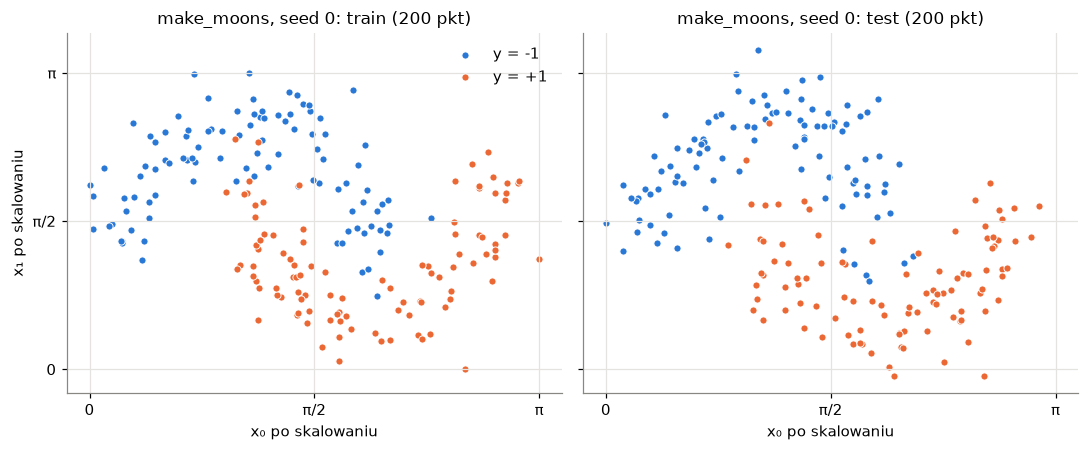

In [3]:
X_tr, X_te, y_tr, y_te = load_data(0)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharex=True, sharey=True)
for ax, (X, y, name) in zip(axes, [(X_tr, y_tr, "train"), (X_te, y_te, "test")]):
    for label, color in [(-1, C_BLUE), (1, C_ORANGE)]:
        mask = y == label
        ax.scatter(X[mask, 0], X[mask, 1], s=22, color=color, edgecolor="white", linewidth=0.6,
                   label=f"y = {label:+d}")
    ax.set(title=f"make_moons, seed 0: {name} ({len(X)} pkt)", xlabel="x₀ po skalowaniu",
           xticks=[0, np.pi / 2, np.pi], xticklabels=["0", "π/2", "π"],
           yticks=[0, np.pi / 2, np.pi], yticklabels=["0", "π/2", "π"])
axes[0].set_ylabel("x₁ po skalowaniu")
axes[0].legend(loc="upper right")
plt.tight_layout()
plt.show()

## 3. Obwód
$R_Y(x_0)$ na $q_0$ i $R_Y(x_1)$ na $q_1$, potem $L$ razy [$R_Y(\theta)$ na każdym kubicie + $\mathrm{CNOT}(0 \to 1)$], na końcu dodatkowa warstwa $R_Y$ na obu kubitach. Liczba parametrów $P = 2(L+1)$. Asercje sprawdzają $P$ oraz liczbę bramek dla każdego $L$. Rysunek pokazuje obwód dla $L = 2$.

P = 2(L+1): {1: 4, 2: 6, 3: 8, 4: 10, 5: 12, 6: 14, 7: 16, 8: 18}


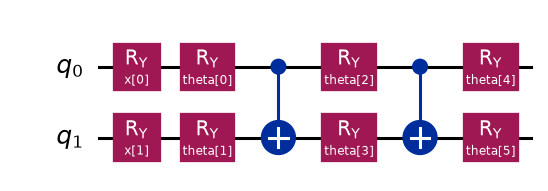

In [4]:
def build_circuit(L):
    x = ParameterVector("x", 2)
    theta = ParameterVector("theta", 2 * (L + 1))
    qc = QuantumCircuit(2)
    qc.ry(x[0], 0)
    qc.ry(x[1], 1)
    for l in range(L):
        qc.ry(theta[2 * l], 0)
        qc.ry(theta[2 * l + 1], 1)
        qc.cx(0, 1)
    qc.ry(theta[2 * L], 0)
    qc.ry(theta[2 * L + 1], 1)
    return qc


for L in LAYERS:
    qc = build_circuit(L)
    ops = qc.count_ops()
    assert qc.num_parameters - 2 == 2 * (L + 1) and ops["cx"] == L and ops["ry"] == 2 + 2 * (L + 1)
print("P = 2(L+1):", {L: build_circuit(L).num_parameters - 2 for L in LAYERS})
build_circuit(2).draw("mpl")

## 4. Forward pass i parameter-shift
- `param_values` buduje tablicę parametrów PUB-a o kształcie ($M$ konfiguracji $\theta$, $N$ punktów, $n_\mathrm{params}$). Kolejność ostatniej osi jest brana z `qc.parameters`. Qiskit sortuje parametry po nazwie, więc kolejność to $\theta_0, \ldots, \theta_{P-1}$, potem $x_0$, $x_1$, a nie kolejność wstawiania bramek.
- `shifted(theta)` zwraca $1 + 2P$ konfiguracji: $\theta$, $\theta + \frac{\pi}{2} e_k$ oraz $\theta - \frac{\pi}{2} e_k$. Jeden PUB liczy więc $f(\theta)$ i wszystkie przesunięcia dla wszystkich punktów naraz.
- Parameter-shift: $\dfrac{\partial f}{\partial \theta_k} = \dfrac{f(\theta + \frac{\pi}{2} e_k) - f(\theta - \frac{\pi}{2} e_k)}{2}$.

In [ ]:
def param_values(qc, X, thetas):
    thetas = np.atleast_2d(thetas)
    vals = np.empty((len(thetas), len(X), qc.num_parameters))
    for j, p in enumerate(qc.parameters):          # kolumny w kolejności qc.parameters
        if p.vector.name == "x":
            vals[:, :, j] = X[None, :, p.index]
        else:
            vals[:, :, j] = thetas[:, None, p.index]
    return vals


def shifted(theta):
    E = SHIFT * np.eye(len(theta))
    return np.vstack([theta, theta + E, theta - E])   


def ps_derivatives(ev, P):
    return (ev[1:P + 1] - ev[P + 1:]) / 2


def predict(f):
    return np.where(f >= 0, 1, -1)                     


def accuracy(f, y):
    return np.mean(predict(f) == y)


print("qc.parameters dla L = 8:", [p.name for p in build_circuit(8).parameters])

qc.parameters dla L = 8: ['theta[0]', 'theta[1]', 'theta[2]', 'theta[3]', 'theta[4]', 'theta[5]', 'theta[6]', 'theta[7]', 'theta[8]', 'theta[9]', 'theta[10]', 'theta[11]', 'theta[12]', 'theta[13]', 'theta[14]', 'theta[15]', 'theta[16]', 'theta[17]', 'x[0]', 'x[1]']


**Uwaga:** ostatnia $R_Y$ na $q_1$ ($\theta_{2L+1}$) stoi po ostatnim CNOT i nie zmienia $\langle Z_0 \rangle$, więc $\partial f / \partial \theta_{2L+1} = 0$. W tabelach podaję $P = 2(L+1)$ zgodnie z planem, ale gradient faktycznie rusza $2L+1$ parametrów.

## 5. Pętla treningowa
Strata to MSE, full batch, Adam zaimplementowany ręcznie ($\mathrm{lr} = 0.1$, $\beta_1 = 0.9$, $\beta_2 = 0.999$, $\varepsilon = 10^{-8}$, z korekcją biasu), init $\theta \sim U(-0.1, 0.1)$ z `np.random.default_rng(seed)`. Na każdą epokę przypada jedno wywołanie `est.run`. Po ostatnim kroku jest jeszcze jedna ewaluacja bez przesunięć, która daje epokę $100$ w historii.

In [ ]:
def train(L, seed, epochs=EPOCHS):
    X_tr, X_te, y_tr, y_te = load_data(seed)
    qc = build_circuit(L)
    P = 2 * (L + 1)
    est = StatevectorEstimator()   # precision = 0 (domyślnie): dokładne wartości oczekiwane, bez shotów
    theta = np.random.default_rng(seed).uniform(-INIT_RANGE, INIT_RANGE, P)
    m, v = np.zeros(P), np.zeros(P)
    history, epoch_times = [], []
    for epoch in range(epochs + 1):
        t0 = time.perf_counter()
        last = epoch == epochs                      
        res = est.run([(qc, OBS, param_values(qc, X_tr, theta if last else shifted(theta))),
                       (qc, OBS, param_values(qc, X_te, theta))]).result()
        ev_tr, f_te = res[0].data.evs, res[1].data.evs[0]
        f_tr = ev_tr[0]
        history.append(dict(L=L, seed=seed, epoch=epoch, train_loss=np.mean((f_tr - y_tr) ** 2),
                            train_acc=accuracy(f_tr, y_tr), test_acc=accuracy(f_te, y_te)))
        if last:
            break
        g = np.mean(2 * (f_tr - y_tr) * ps_derivatives(ev_tr, P), axis=1)   
        t = epoch + 1
        m = BETA1 * m + (1 - BETA1) * g
        v = BETA2 * v + (1 - BETA2) * g ** 2
        theta = theta - LR * (m / (1 - BETA1 ** t)) / (np.sqrt(v / (1 - BETA2 ** t)) + EPS)
        epoch_times.append(time.perf_counter() - t0)
    return history, float(np.mean(epoch_times))

## 6. Pełny eksperyment
$8$ wartości $L$ $\times$ $5$ seedów $\times$ $100$ epok. Runy liczą się równolegle (`joblib`, największe $L$ idą pierwsze). Wyniki trafiają do `results/history.csv` (per $L$, seed, epoka: train loss, train acc, test acc) i `results/final.csv` (per $L$, seed: końcowe train acc, test acc, luka $=$ train $-$ test). Jeśli oba pliki już istnieją, a `RETRAIN = False`, komórka tylko je wczytuje.

In [11]:
RETRAIN = False
hist_path, final_path = RESULTS / "history.csv", RESULTS / "final.csv"

if RETRAIN or not (hist_path.exists() and final_path.exists()):
    jobs = [(L, s) for L in sorted(LAYERS, reverse=True) for s in SEEDS]
    t0 = time.time()   # time.time, bo perf_counter na macOS nie liczy czasu uśpienia
    out = Parallel(n_jobs=-1, verbose=5)(delayed(train)(L, s) for L, s in jobs)
    wall = time.time() - t0
    history = (pd.DataFrame([row for hist, _ in out for row in hist])
               .sort_values(["L", "seed", "epoch"]).reset_index(drop=True))
    final = history[history.epoch == EPOCHS][["L", "seed", "train_acc", "test_acc"]].reset_index(drop=True)
    final["gap"] = final.train_acc - final.test_acc
    history.to_csv(hist_path, index=False)
    final.to_csv(final_path, index=False)
    print(f"trening: {len(jobs)} runów w {wall / 60:.1f} min (wall-clock)")
else:
    history, final = pd.read_csv(hist_path), pd.read_csv(final_path)
    print(f"wczytano {hist_path} i {final_path} (RETRAIN = False)")

assert len(final) == len(LAYERS) * len(SEEDS)
assert (history.groupby(["L", "seed"]).size() == EPOCHS + 1).all()
final

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.


[Parallel(n_jobs=-1)]: Done   2 tasks      | elapsed:  8.6min


[Parallel(n_jobs=-1)]: Done  34 out of  40 | elapsed: 28.1min remaining:  5.0min


trening: 40 runów w 28.6 min (wall-clock); szacunek z sekcji 5: 97 min sekwencyjnie


[Parallel(n_jobs=-1)]: Done  40 out of  40 | elapsed: 28.6min finished


,L,seed,train_acc,test_acc,gap
0,1,0,0.850,0.905,-0.055
1,1,1,0.865,0.845,0.020
2,1,2,0.890,0.845,0.045
3,1,3,0.865,0.890,-0.025
4,1,4,0.855,0.870,-0.015
5,2,0,0.845,0.905,-0.060
6,2,1,0.870,0.850,0.020
7,2,2,0.885,0.845,0.040
8,2,3,0.855,0.900,-0.045
9,2,4,0.850,0.875,-0.025


## 7. Wykresy
Średnia po $5$ seedach.

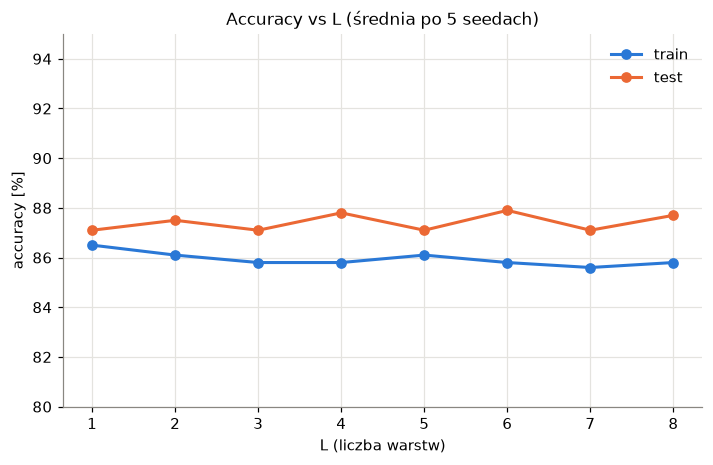

In [12]:
agg = final.groupby("L").agg(
    train_mean=("train_acc", "mean"), train_std=("train_acc", "std"),
    test_mean=("test_acc", "mean"), test_std=("test_acc", "std"),
    gap_mean=("gap", "mean"), gap_std=("gap", "std"))
L_arr = agg.index.to_numpy()

fig, ax = plt.subplots(figsize=(7.5, 4.4))
for col, color in [("train", C_BLUE), ("test", C_ORANGE)]:
    ax.plot(L_arr, 100 * agg[f"{col}_mean"], color=color, marker="o", ms=6, lw=2, label=col)
ax.set(xlabel="L (liczba warstw)", ylabel="accuracy [%]", xticks=LAYERS, ylim=(80, 95),
       title="Accuracy vs L (średnia po 5 seedach)")
ax.legend()
fig.savefig(PLOTS / "accuracy_vs_L.png", dpi=150, bbox_inches="tight")
plt.show()

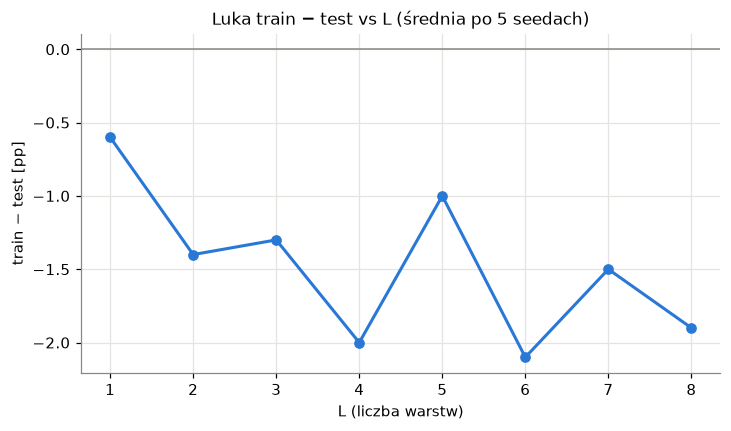

In [13]:
fig, ax = plt.subplots(figsize=(7.5, 4.0))
ax.axhline(0, color=INK_MUTED, lw=1)
ax.plot(L_arr, 100 * agg.gap_mean, color=C_BLUE, marker="o", ms=6, lw=2)
ax.set(xlabel="L (liczba warstw)", ylabel="train − test [pp]", xticks=LAYERS,
       title="Luka train − test vs L (średnia po 5 seedach)")
fig.savefig(PLOTS / "gap_vs_L.png", dpi=150, bbox_inches="tight")
plt.show()

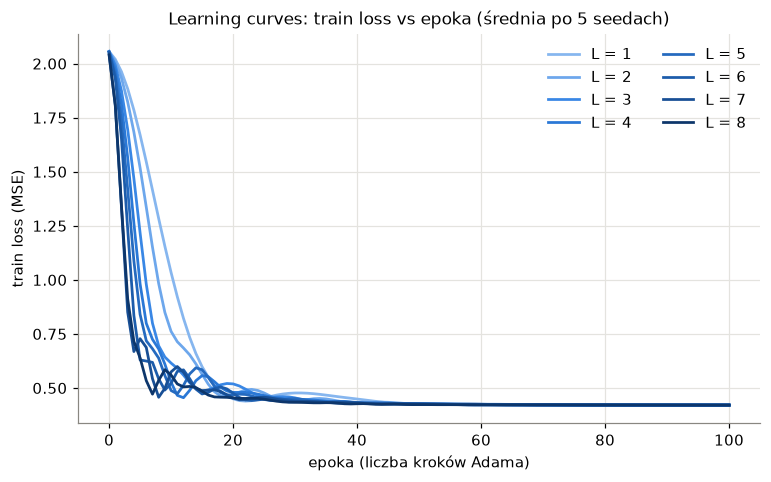

In [14]:
curves = history.groupby(["L", "epoch"]).train_loss.mean().unstack("L")

fig, ax = plt.subplots(figsize=(8, 4.6))
for L, color in zip(LAYERS, RAMP_L):
    ax.plot(curves.index, curves[L], color=color, lw=1.8, label=f"L = {L}")
ax.set(xlabel="epoka (liczba kroków Adama)", ylabel="train loss (MSE)",
       title="Learning curves: train loss vs epoka (średnia po 5 seedach)")
ax.legend(ncols=2)
fig.savefig(PLOTS / "learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()

W zasadzie $50$ epok byłoby zdecydowanie wystarczające, ponieważ loss się wtedy stabilizuje.

## 8. Tabela wyników
Średnia $\pm$ std po $5$ seedach, wyniki po $100$ epokach. Accuracy w $\%$, luka w pp.

In [15]:
pm = lambda col: [f"{100 * m:.1f} ± {100 * s:.1f}" for m, s in zip(agg[f"{col}_mean"], agg[f"{col}_std"])]
table = pd.DataFrame({"L": L_arr, "P": 2 * (L_arr + 1), "train acc [%]": pm("train"),
                      "test acc [%]": pm("test"), "luka train − test [pp]": pm("gap")}).set_index("L")
table

,P,train acc [%],test acc [%],luka train − test [pp]
L,,,,
1,4,86.5 ± 1.5,87.1 ± 2.7,-0.6 ± 3.9
2,6,86.1 ± 1.6,87.5 ± 2.8,-1.4 ± 4.3
3,8,85.8 ± 2.0,87.1 ± 2.8,-1.3 ± 4.4
4,10,85.8 ± 1.8,87.8 ± 2.8,-2.0 ± 4.4
5,12,86.1 ± 1.8,87.1 ± 2.9,-1.0 ± 4.1
6,14,85.8 ± 1.8,87.9 ± 2.7,-2.1 ± 4.3
7,16,85.6 ± 1.8,87.1 ± 2.7,-1.5 ± 4.2
8,18,85.8 ± 2.2,87.7 ± 2.7,-1.9 ± 4.7


## 9. Czy moja hipoteza się sprawdziła?
Moja hipoteza w dużym skrócie (wszystkie liczby to średnia z $5$ seedów): $(1)$ najwyższa test accuracy dla $L = 2$ lub $L = 3$, $(2)$ test accuracy dla $L = 1$ co najmniej $3$ pp poniżej maksimum, $(3)$ to samo dla $L = 8$.

Jak widać z powyższych wyników, absolutnie się myliłem we wszystkich trzech częściach hipotezy. Płaskie wyniki wynikają z budowy obwodu: dane wchodzą tylko raz, a od $L = 2$ model ma tylko $4$ niezależne kierunki zmian, mimo że $P$ rośnie do $18$. Następnym razem może warto spróbować data re-uploading, czyli powtarzanie $R_Y(x_i)$ w każdej warstwie.

Z ciekawszych obserwacji na wynikach eksperymentu:
 - model radzi sobie lepiej na zbiorze testowym niż na treningowym
 - parzyste $L$ mają o $0.6$ pp wyższy test, czyli około $1$ punkt z $200$, przy $5$ seedach to nieodróżnialne od szumu.